In [1]:
from pathlib import Path
import sys
from itertools import combinations
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT=Path.cwd()
if not (PROJECT_ROOT/'ypipe').is_dir(): PROJECT_ROOT=PROJECT_ROOT.parent
sys.path.insert(0,str(PROJECT_ROOT))
from ypipe import config, features

SEED=42
np.random.seed(SEED)
MIN_SUPPORT=0.02  # tối thiểu 2% số phiên có category để tránh luật quá hiếm
MIN_CONFIDENCE=0.20  # ngưỡng lọc ban đầu cho xác suất đồng xuất hiện có điều kiện
MAX_ITEMSET_SIZE=3  # giới hạn 3 category để số tổ hợp còn diễn giải được
MIN_COMBO_VIDEOS=10  # mỗi combo thuộc tính cần ít nhất 10 video để trung vị bớt nhiễu
N_TOP_RULES=25
config.DATA.mkdir(parents=True,exist_ok=True)
_previous_con = globals().get('con')
if _previous_con is not None:
    try:
        _previous_con.close()
    except Exception:
        pass
class _NotebookQueryResult:
    def __init__(self, frame):
        self._frame = frame
    def df(self):
        return self._frame.copy()
    def fetchdf(self):
        return self._frame.copy()
    def fetchone(self):
        if self._frame.empty:
            return None
        return tuple(self._frame.iloc[0].tolist())
    def fetchall(self):
        return list(self._frame.itertuples(index=False, name=None))

class _NotebookReadOnlyDB:
    """Run each read query on a short-lived connection to avoid retaining a file lock."""
    def __init__(self, path):
        self.path = Path(path)
    def execute(self, sql, parameters=None):
        if not self.path.exists():
            if sql.strip().lower() == 'show tables':
                return _NotebookQueryResult(pd.DataFrame({'name': pd.Series(dtype='object')}))
            return _NotebookQueryResult(pd.DataFrame())
        db = duckdb.connect(str(self.path), read_only=True)
        try:
            result = db.execute(sql) if parameters is None else db.execute(sql, parameters)
            frame = result.fetchdf()
        finally:
            db.close()
        return _NotebookQueryResult(frame)
    def close(self):
        # Queries already close their own connection before returning.
        return None

con=_NotebookReadOnlyDB(config.DB_PATH)
TABLES=set(con.execute('SHOW TABLES').fetchdf()['name'])
print(f'Database: {config.DB_PATH} | seed={SEED} | ngắt phiên={config.SESSION_GAP_MIN} phút')

Database: D:\project\bigdata\data\warehouse.duckdb | seed=42 | ngắt phiên=30 phút


# Tổ hợp thể loại và thuộc tính — Stage 5

## Câu hỏi
Những thể loại nào thường cùng xuất hiện trong một phiên? Combo thể loại × độ dài × khung giờ đăng nào có trung vị `views_per_day` cao hơn?

## Phương pháp
Tạo giỏ thể loại theo phiên bằng `features.build_events` và ngưỡng phiên trong `config`. Duyệt itemset tối đa 3 thể loại theo cách Apriori đơn giản; xếp luật theo support, confidence và lift. Với combo thuộc tính video, nhóm video còn metadata theo thể loại × bucket thời lượng × khung giờ đăng và tính trung vị `views_per_day`. Các ngưỡng support, confidence và số video tối thiểu nằm ở cell đầu.

In [2]:
raw=con.execute('SELECT * FROM watch_raw').df() if 'watch_raw' in TABLES else pd.DataFrame()
meta=con.execute('SELECT * FROM video_metadata').df() if 'video_metadata' in TABLES else pd.DataFrame()
facts=con.execute('SELECT * FROM video_facts').df() if 'video_facts' in TABLES else pd.DataFrame()

if len(raw) and len(meta):
    events=features.build_events(raw,meta)
else:
    events=pd.DataFrame(columns=['session_id','video_id','category_name'])

category_events=events[['session_id','video_id']].merge(
    facts.loc[facts['metadata_status'].eq('ok'),['video_id','category_name']] if len(facts) else pd.DataFrame(columns=['video_id','category_name']),
    on='video_id',how='inner').dropna(subset=['category_name'])
baskets=[set(g['category_name'].astype(str)) for _,g in category_events.groupby('session_id') if len(g)]
items=sorted(set().union(*baskets)) if baskets else []
n_baskets=len(baskets)

support_counts={}
for size in range(1,min(MAX_ITEMSET_SIZE,len(items))+1):
    for itemset in combinations(items,size):
        support_counts[frozenset(itemset)]=sum(set(itemset).issubset(basket) for basket in baskets)

rules=[]
for itemset,count in support_counts.items():
    if len(itemset)<2 or count/max(n_baskets,1)<MIN_SUPPORT: continue
    ordered=sorted(itemset)
    for antecedent_size in range(1,len(ordered)):
        for antecedent_tuple in combinations(ordered,antecedent_size):
            antecedent=frozenset(antecedent_tuple); consequent=itemset-antecedent
            antecedent_count=support_counts.get(antecedent,0)
            consequent_count=support_counts.get(consequent,0)
            if antecedent_count==0 or consequent_count==0: continue
            support=count/n_baskets
            confidence=count/antecedent_count
            lift=confidence/(consequent_count/n_baskets)
            if confidence>=MIN_CONFIDENCE:
                rules.append({'Nếu có':', '.join(sorted(antecedent)),
                              'Thì thường có':', '.join(sorted(consequent)),
                              'Support':support,'Confidence':confidence,'Lift':lift,'Số phiên':count})
rule_table=pd.DataFrame(rules).sort_values(['Lift','Support'],ascending=False).head(N_TOP_RULES) if rules else pd.DataFrame()
print(f'Phiên có category: {n_baskets:,}; thể loại khác nhau: {len(items)}; luật sau lọc: {len(rules):,}')

Phiên có category: 19,292; thể loại khác nhau: 15; luật sau lọc: 313


## Kết quả: luật kết hợp trong phiên
Support là tỷ lệ phiên chứa cả hai vế; confidence là tỷ lệ phiên có antecedent cũng chứa consequent; lift so sánh confidence với tần suất consequent. Lift lớn hơn 1 thể hiện đồng xuất hiện cao hơn mức nền, không có nghĩa thể loại bên trái gây ra thể loại bên phải.

,Nếu có,Thì thường có,Support,Confidence,Lift,Số phiên
83,Autos & Vehicles,"Entertainment, Sports",0.021771,0.353535,5.509212,420
87,"Entertainment, Sports",Autos & Vehicles,0.021771,0.339257,5.509212,420
84,Sports,"Autos & Vehicles, Entertainment",0.021771,0.243478,4.997003,420
85,"Autos & Vehicles, Entertainment",Sports,0.021771,0.446809,4.997003,420
99,Autos & Vehicles,"People & Blogs, Sports",0.022911,0.372054,4.991421,442
103,"People & Blogs, Sports",Autos & Vehicles,0.022911,0.307371,4.991421,442
59,Sports,News & Politics,0.020164,0.225507,4.713419,389
58,News & Politics,Sports,0.020164,0.421452,4.713419,389
100,Sports,"Autos & Vehicles, People & Blogs",0.022911,0.256232,4.589810,442
101,"Autos & Vehicles, People & Blogs",Sports,0.022911,0.410399,4.589810,442


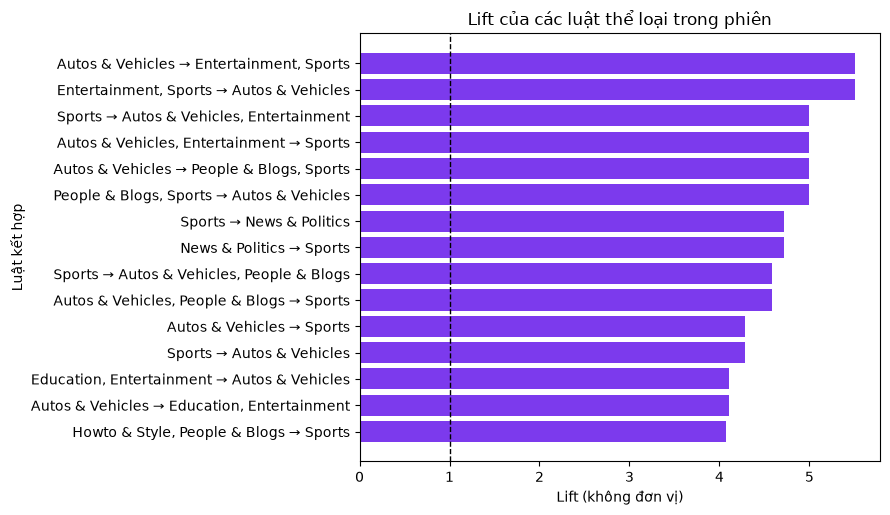

In [3]:
if len(rule_table):
    display(rule_table)
    plot_rules=rule_table.head(15).iloc[::-1]
    fig,ax=plt.subplots(figsize=(9,max(3,0.35*len(plot_rules))))
    ax.barh(plot_rules['Nếu có']+' → '+plot_rules['Thì thường có'],plot_rules['Lift'],color='#7c3aed')
    ax.axvline(1,color='black',linewidth=1,linestyle='--')
    ax.set_title('Lift của các luật thể loại trong phiên'); ax.set_xlabel('Lift (không đơn vị)'); ax.set_ylabel('Luật kết hợp')
    plt.tight_layout(); plt.show()
else:
    print('Chưa có luật thỏa MIN_SUPPORT và MIN_CONFIDENCE; thử kiểm tra độ nhạy các ngưỡng trước khi hạ chúng.')

## Kết quả: combo thuộc tính video
Thời lượng được gom thành Shorts/1–5/5–20/20–60/>60 phút; giờ đăng dùng khung giờ Việt Nam đã lưu trong `video_facts`. Chỉ giữ combo có ít nhất `MIN_COMBO_VIDEOS` video.

,Thể loại,Độ dài,Khung giờ đăng,Số video,Trung vị views/ngày
215,Pets & Animals,≤1 phút,Đêm (22–5h),25,223202.083255
251,Sports,≤1 phút,Đêm (22–5h),120,108494.219121
21,Comedy,≤1 phút,Đêm (22–5h),48,72626.960200
60,Entertainment,≤1 phút,Đêm (22–5h),531,34872.330297
231,Science & Technology,≤1 phút,Đêm (22–5h),202,32424.885719
0,Autos & Vehicles,≤1 phút,Chiều (12–18h),168,31296.336500
119,Howto & Style,≤1 phút,Tối (18–22h),167,28749.753485
40,Education,≤1 phút,Đêm (22–5h),194,24457.066935
177,Nonprofits & Activism,≤1 phút,Chiều (12–18h),12,24172.295235
3,Autos & Vehicles,≤1 phút,Đêm (22–5h),31,24093.658482


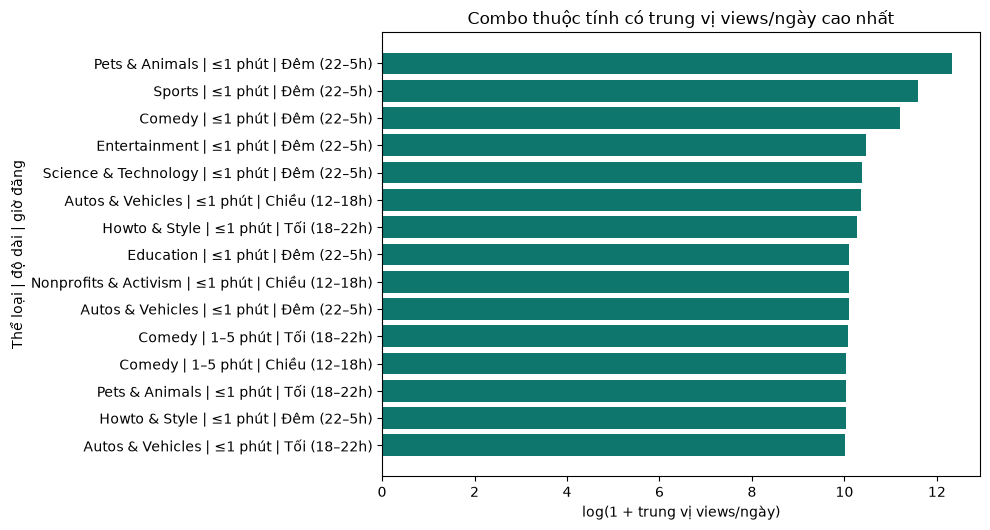

In [4]:
if len(facts):
    video_data=facts[(facts['metadata_status']=='ok') & facts['views_per_day'].notna()].copy()
    video_data['category_name']=video_data['category_name'].fillna('Chưa phân loại')
    video_data['length_bucket']=pd.cut(video_data['duration_sec'],[-np.inf,60,300,1200,3600,np.inf],
        labels=['≤1 phút','1–5 phút','5–20 phút','20–60 phút','>60 phút'],include_lowest=True)
    def daypart(hour):
        if pd.isna(hour): return 'Chưa rõ'
        hour=int(hour)
        if 5<=hour<12: return 'Sáng (5–12h)'
        if 12<=hour<18: return 'Chiều (12–18h)'
        if 18<=hour<22: return 'Tối (18–22h)'
        return 'Đêm (22–5h)'
    video_data['publish_daypart']=video_data['pub_hour'].map(daypart)
    attribute_summary=(video_data.groupby(['category_name','length_bucket','publish_daypart'],observed=True)
        .agg(n_videos=('video_id','nunique'),median_views_per_day=('views_per_day','median'))
        .reset_index())
    attribute_summary=attribute_summary[attribute_summary.n_videos>=MIN_COMBO_VIDEOS].sort_values('median_views_per_day',ascending=False)
else:
    video_data=pd.DataFrame(); attribute_summary=pd.DataFrame()

if len(attribute_summary):
    display(attribute_summary.rename(columns={'category_name':'Thể loại','length_bucket':'Độ dài','publish_daypart':'Khung giờ đăng','n_videos':'Số video','median_views_per_day':'Trung vị views/ngày'}).head(30))
    plot_attr=attribute_summary.head(15).iloc[::-1]
    labels=plot_attr['category_name'].astype(str)+' | '+plot_attr['length_bucket'].astype(str)+' | '+plot_attr['publish_daypart'].astype(str)
    fig,ax=plt.subplots(figsize=(10,max(3,0.36*len(plot_attr))))
    ax.barh(labels,np.log1p(plot_attr['median_views_per_day']),color='#0f766e')
    ax.set_title('Combo thuộc tính có trung vị views/ngày cao nhất')
    ax.set_xlabel('log(1 + trung vị views/ngày)'); ax.set_ylabel('Thể loại | độ dài | giờ đăng')
    plt.tight_layout(); plt.show()
else:
    print(f'Không có combo đạt tối thiểu {MIN_COMBO_VIDEOS} video.')

con.close()

## Insight
Các luật và combo mô tả mẫu đồng xuất hiện trong dữ liệu quan sát. Nên xem cả support và số phiên/video cùng lift hoặc trung vị; một lift cao trên mẫu nhỏ có thể không ổn định.

## Hạn chế
Phiên được xác định bằng khoảng im lặng cấu hình, không phải ranh giới hành vi quan sát trực tiếp. Giỏ phiên chỉ tính video có thể loại và metadata thành công. `views_per_day` là tốc độ trung bình từ ảnh chụp API và tuổi video, không phải tốc độ tại thời điểm xem. Thời điểm đăng và hiệu suất có thể bị ảnh hưởng bởi nhiều yếu tố không quan sát; không suy ra nhân quả. Các ngưỡng 2% support, confidence 0,20 và 10 video/combo là giả định ban đầu, cần kiểm tra độ nhạy.